# VGG-11 end-to-end extraction: bit-wise accuracy vs trace count

For each trace count, the **layer where extraction crashes** (bit-wise acc `<= 0.30`) and the per-layer
accuracy curve up to that point.

**All values are computed by `postprocess.py`** (→ `./data/*.csv`) from the recovered per-filter weights on disk
(`../N0.0/seed8/vgg_e2e/HD/cifar6moutput/<traces>/<layer>/filter_*.pkl`) compared bit-exact (float16) to
ground truth (`../model_weights/<layer>/...`). Trace counts are auto-discovered from disk; a layer counts
only if **all** its filters are present (the crash layer is the last fully-extracted layer; the orchestrator's
partial next-layer is ignored). These are the *as-extracted* weights, so a few sign-corrected mid-layers may
read slightly below the logged post-correction figures — the crash points are unchanged.

In [1]:
import os, glob, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# --- layer order + friendly names (forward order) ---
LAYER_ORDER = ['features.0','features.4','features.8','features.11','features.15',
               'features.18','features.22','features.25','classifier.0','classifier.3','classifier.6']
LAYER_NAMES = {'features.0':'conv1','features.4':'conv2','features.8':'conv3','features.11':'conv4',
               'features.15':'conv5','features.18':'conv6','features.22':'conv7','features.25':'conv8',
               'classifier.0':'fc1','classifier.3':'fc2','classifier.6':'fc3'}

In [3]:
# --- (trace count, layer) bit-wise accuracies, computed by postprocess.py ---
df    = pd.read_csv('data/bitwise_acc.csv', dtype={'num_traces': str})
crash = pd.read_csv('data/crash_layer_by_traces.csv', dtype={'num_traces': str})
RUNS  = crash['num_traces'].tolist()
print('trace dirs found:', RUNS)

DATA = {run: {} for run in RUNS}
for r in df.itertuples():
    DATA[r.num_traces][r.layer_key] = r.bitwise_acc

trace dirs found: ['500', '1k', '2k', '5k', '10k', '20k', '40k']


## Table — trace count vs. the layer extraction crashed upon

Runs that complete the whole network have `-`.

In [4]:
summary = crash.set_index('num_traces')[['crashed_at']]
summary

,crashed_at
num_traces,
500,conv3
1k,conv5
2k,conv6
5k,conv8
10k,fc1
20k,-
40k,-


## Backup — full per-layer bit-wise accuracy matrix (computed from disk)

In [5]:
matrix = pd.DataFrame(index=[LAYER_NAMES[l] for l in LAYER_ORDER], columns=RUNS, dtype=float)
for run in RUNS:
    for layer, a in DATA[run].items():
        matrix.loc[LAYER_NAMES[layer], run] = a
matrix.index.name = 'layer'
matrix.round(4)

,500,1k,2k,5k,10k,20k,40k
layer,,,,,,,
conv1,0.9983,1.0000,0.9994,0.9994,0.9994,1.0000,1.0000
conv2,0.9024,0.9510,0.9734,0.9877,0.9925,0.9959,0.9971
conv3,0.0311,0.9484,0.9841,0.9967,0.9985,0.9994,0.9997
conv4,NaN,0.3849,0.8889,0.9809,0.9918,0.9972,0.9983
conv5,NaN,0.0000,0.7002,0.9574,0.9815,0.9921,0.9939
conv6,NaN,NaN,0.0046,0.8341,0.9317,0.9769,0.9861
conv7,NaN,NaN,NaN,0.6088,0.8088,0.9035,0.9399
conv8,NaN,NaN,NaN,0.0072,0.8076,0.9353,0.9653
fc1,NaN,NaN,NaN,NaN,0.2393,0.9790,0.9826


## Graph — bit-wise accuracy per layer, up to failure

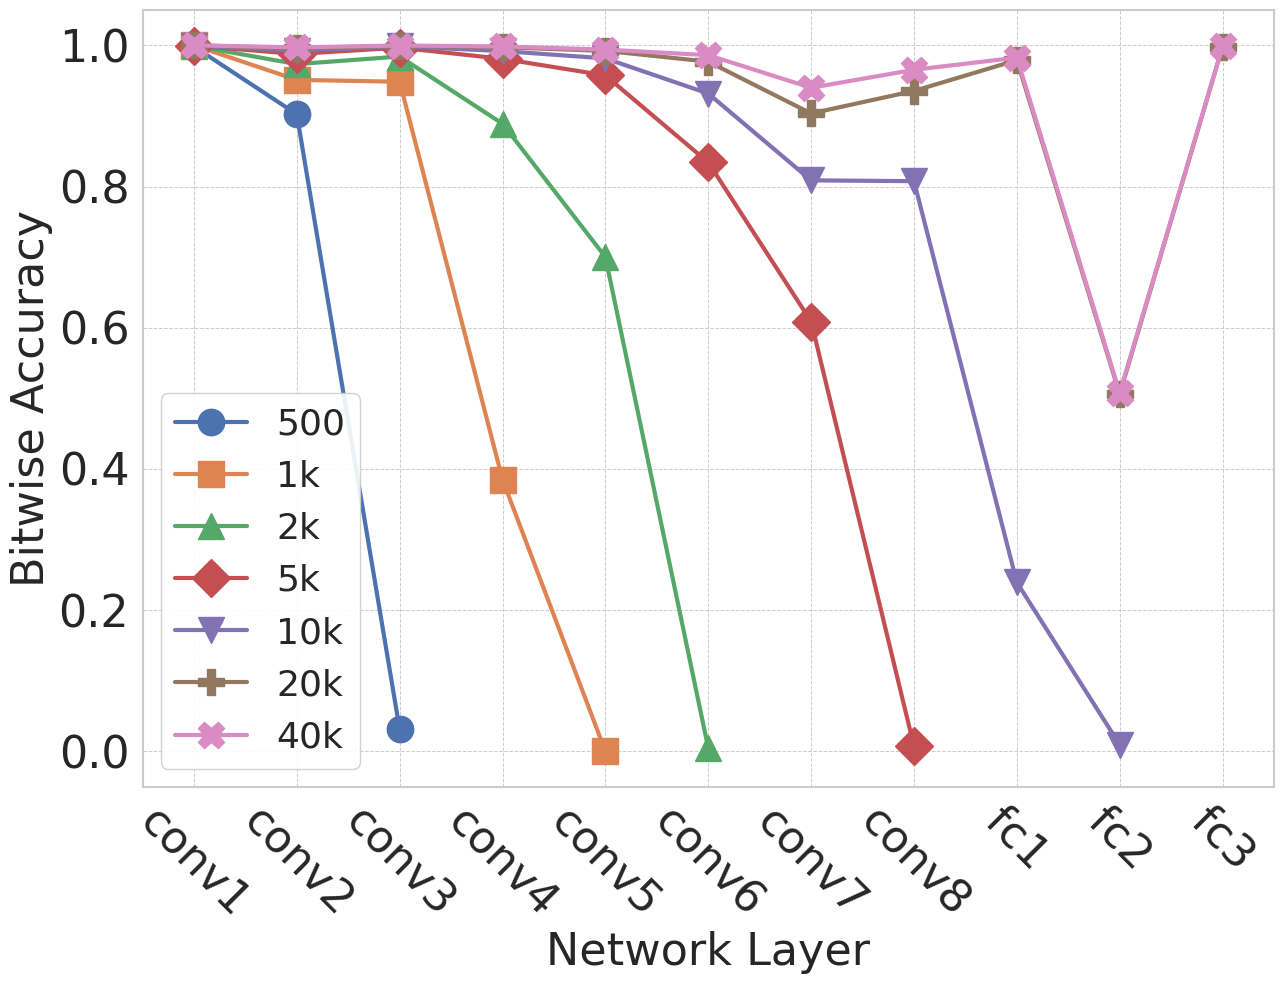

saved -> ../plots/bitwise_acc_up_to_failure.pdf


In [6]:
def plot_bitwise_acc_per_layer(
    layers,
    accs_dict,                 # dict: line label -> list of per-layer bitwise accuracies (NaN -> line stops)
    figsize=(13, 9),
    font_size=32,
    marker_size=17,
    linewidth=3,
    xlabel='Network Layer',
    ylabel='Bitwise Accuracy',
    savepath='../plots/bitwise_acc_up_to_failure.pdf',
):
    """One line per run; x-axis = network layers. Same dimensions/style as the
    e2e_vs_norun0 notebook's plot_bitwise_acc_per_layer."""
    sns.set(style='whitegrid')
    fig, ax = plt.subplots(figsize=figsize)
    x = np.arange(len(layers))
    marker_cycle = ['o', 's', '^', 'D', 'v', 'P', 'X', '*', 'h']

    for i, (label, accs) in enumerate(accs_dict.items()):
        ax.plot(
            x, np.asarray(accs, dtype=float),
            marker=marker_cycle[i % len(marker_cycle)],
            linewidth=linewidth, markersize=marker_size, label=label,
        )


    ax.set_xlabel(xlabel, fontsize=font_size)
    ax.set_ylabel(ylabel, fontsize=font_size)
    ax.set_xticks(x)
    ax.set_xticklabels(layers, rotation=-45, ha='center', fontsize=font_size)
    ax.tick_params(axis='y', labelsize=font_size)

    ax.grid(True, which='both', linestyle='--', linewidth=0.7)
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
    ax.legend(fontsize=26, framealpha=0.9, loc='lower left', ncol=1)

    plt.tight_layout()
    os.makedirs(os.path.dirname(savepath), exist_ok=True)
    plt.savefig(savepath, format='pdf', bbox_inches='tight', metadata={'Creator': 'Matplotlib'})
    plt.show()


layers     = [LAYER_NAMES[l] for l in LAYER_ORDER]
GRAPH_RUNS = list(RUNS)                           # all runs, including 500
accs_dict  = {f'{run}': [DATA[run].get(l, np.nan) for l in LAYER_ORDER] for run in GRAPH_RUNS}

plot_bitwise_acc_per_layer(
    layers=layers,
    accs_dict=accs_dict,
    figsize=(13, 10),
    font_size=32,
    marker_size=19,
    savepath='../plots/bitwise_acc_up_to_failure.pdf',
)
print('saved -> ../plots/bitwise_acc_up_to_failure.pdf')